# Phân tích ngành Hàng tiêu dùng thiết yếu trên HOSE (10/2024 – 10/2026)


## 0. Cấu hình và hàm dùng chung
**Mục đích:** khai báo thư mục dữ liệu, màu sắc và 4 hàm nhỏ dùng chung cho mọi biểu đồ.


In [2]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.3 MB 4.2 MB/s eta 0:00:03
   ---- ----------------------------------- 1.0/9.3 MB 3.1 MB/s eta 0:00:03
   ----- ---------------------------------- 1.3/9.3 MB 2.4 MB/s eta 0:00:04
   ------ --------------------------------- 1.6/9.3 MB 2.0 MB/s eta 0:00:04
   ------- -------------------------------- 1.8/9.3 MB 1.9 MB/s eta 0:00:04
   -------- ------------------------------- 2.1/9.3 MB 1.8 MB/s eta 0:00:05
   ---------- ----------------------------- 2.4/9.3 MB 1.7 MB/s eta 0:00:05
   ----------- ---------------------------- 2.6/9.3 MB 1.5 MB/s eta 0:00:05
   ------------ --------------------------- 2.9/9.3 MB 1.5 MB/s eta 0:00:05
   ------------ --------------------------- 2.9/9.3 MB 1.5 MB/s eta 0:00:05
   ------------ --------------------------- 2.9/9.3 MB 1.5 MB/s eta 0:00:05
   ------------- --------------


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os, glob, textwrap, unicodedata
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from matplotlib.lines import Line2D

try:
    from adjustText import adjust_text          # gắn nhãn điểm không bị chồng
except ImportError:
    %pip install adjustText -q
    from adjustText import adjust_text

# ---- đường dẫn ----
# Cấu trúc dự án:  DuAn_ConsumerStaples/outputs/  (Truy_van_*.csv)  ->  notebook (src/)  ->  dashboard/ (Hình 1..10)
def tim_goc_du_an():
    """Đi ngược từ thư mục đang chạy notebook lên đến khi gặp thư mục 'outputs'."""
    thu_muc = os.path.abspath(os.getcwd())
    while True:
        if os.path.isdir(os.path.join(thu_muc, "outputs")):
            return thu_muc
        cha = os.path.dirname(thu_muc)
        if cha == thu_muc:
            raise FileNotFoundError("Không tìm thấy thư mục 'outputs'. Hãy mở notebook từ bên trong thư mục dự án.")
        thu_muc = cha

ROOT     = tim_goc_du_an()
DATA_DIR = os.environ.get("DATA_DIR", os.path.join(ROOT, "outputs"))   # thư mục chứa các file Truy_van_*.csv
OUT_DIR  = os.path.join(ROOT, "dashboard")                              # nơi lưu Hình 1 -> Hình 10
SAVE_PNG = True                                                         # False nếu chỉ muốn xem trong notebook
TEN_HINH = "Hình {}.png"                                                # đổi thành "hinh_{:02d}.png" nếu muốn tên không dấu
os.makedirs(OUT_DIR, exist_ok=True)
print("Đọc dữ liệu từ:", DATA_DIR)
print("Lưu hình vào  :", OUT_DIR)

# ---- màu sắc ----
XANH_LA, DO, XANH_DUONG = "#2E7D5B", "#C0392B", "#2F5D8C"
XAM, DEN, CAM, TIM = "#9AA3AB", "#2B3640", "#E08E0B", "#7B5EA7"

mpl.rcParams.update({
    "font.family": "DejaVu Sans", "savefig.dpi": 160,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#E6EAEE", "axes.axisbelow": True,
})

# ---- hàm dùng chung ----
def tim_file(mau):
    """Tìm file theo mẫu tên trong DATA_DIR."""
    ket_qua = glob.glob(os.path.join(DATA_DIR, mau))
    assert ket_qua, f"Không tìm thấy file '{mau}' trong thư mục '{DATA_DIR}'"
    return ket_qua[0]

def so_vn(x, so_le=1, co_dau=False):
    """Số kiểu Việt Nam: 12,3 và −4,5 (co_dau=True thì thêm dấu + cho số dương)."""
    chu = f"{x:+.{so_le}f}" if co_dau else f"{x:.{so_le}f}"
    if co_dau and float(chu) == 0:
        chu = f"{0:.{so_le}f}"
    return chu.replace(".", ",").replace("-", "−")

def nghin(x):
    """Số nguyên có dấu chấm ngăn hàng nghìn: 12.345."""
    return f"{int(round(x)):,}".replace(",", ".")

def luu_hinh(fig, so_hinh, dpi=None):
    """Lưu ảnh vào thư mục dashboard với tên 'Hình <số>.png'."""
    if SAVE_PNG:
        ten = unicodedata.normalize("NFC", TEN_HINH.format(so_hinh))   # chuẩn hóa dấu tiếng Việt, tránh lỗi tên file giữa Windows/macOS
        tuy_chon = {"dpi": dpi} if dpi else {}
        fig.savefig(os.path.join(OUT_DIR, ten), facecolor="white", **tuy_chon)

def ve_xong(fig, tieu_de, so_hinh):
    """Gắn tiêu đề (luận điểm), lưu ảnh và hiển thị."""
    fig.suptitle(textwrap.fill(tieu_de, int(fig.get_figwidth() * 9)), x=0.01, ha="left", fontsize=14, fontweight="bold", color=DEN)
    luu_hinh(fig, so_hinh)
    plt.show()
    plt.close(fig)


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Đọc dữ liệu từ: c:\Users\ASUS\Documents\Project DA\DuAn_ConsumerStaples\outputs
Lưu hình vào  : c:\Users\ASUS\Documents\Project DA\DuAn_ConsumerStaples\dashboard


## 1. Đọc dữ liệu


In [4]:
# ---- đọc 7 file truy vấn (từ thư mục outputs/) ----
q1 = pd.read_csv(tim_file("Truy*1.csv"))     # dòng tiền theo tháng
q3 = pd.read_csv(tim_file("Truy*3.csv"))     # lợi nhuận, Max Drawdown, lợi nhuận/rủi ro (30 mã)
q4 = pd.read_csv(tim_file("Truy*4.csv"))     # cảnh báo thanh khoản (8 mã)
q5 = pd.read_csv(tim_file("Truy*5.csv"))     # phân nhóm (35 mã)
q6 = pd.read_csv(tim_file("Truy*6.csv"))     # trung bình / trung vị
q7 = pd.read_csv(tim_file("Truy*7.csv"))     # tổng giá trị khớp theo mã
q8 = pd.read_csv(tim_file("Truy*8.csv"))     # chuỗi theo ngày của SSC, SBT

for ten, bang in dict(q1=q1, q3=q3, q4=q4, q5=q5, q6=q6, q7=q7, q8=q8).items():
    print(f"{ten}: {bang.shape[0]} dòng x {bang.shape[1]} cột")

# ---- chuẩn bị 1: q1, bỏ tháng đầu (10/2024) và tháng cuối (10/2026) vì chưa đủ tháng ----
thang_du = q1.iloc[1:-1].reset_index(drop=True)
thang_du["Nhan"] = thang_du.Thang.str[5:] + "/" + thang_du.Thang.str[2:4]     # '2025-03' -> '03/25'

# ---- chuẩn bị 2: q5, đổi tên nhóm thành mã ngắn (A, B, C, D, T, N) ----
def ma_nhom(ten):
    if ten.startswith("Xep"):   return "N"        # niêm yết mới, xếp riêng
    if ten.startswith("Trung"): return "T"        # trung tính
    return ten[0]                                  # A, B, C, D

q5["Nhom_ma"] = q5.Nhom.map(ma_nhom)
TEN_NHOM = {"A": "A. Ưu tiên theo dõi", "B": "B. Thận trọng – thanh khoản", "C": "C. Thận trọng – lỗ và sụt sâu",
            "D": "D. Lời nhưng từng sụt rất sâu", "T": "Trung tính", "N": "Niêm yết mới (xếp riêng)"}
MAU_NHOM = {"A": XANH_LA, "B": CAM, "C": DO, "D": TIM, "T": XAM, "N": DEN}

# ---- chuẩn bị 3: q8, chỉ số giá điều chỉnh (ngày đầu = 100) ----
q8["Ngay"] = pd.to_datetime(q8["Ngay"])
q8["Chi_so_gia"] = 100 * (1 + q8.Cumulative_Return)

q1: 25 dòng x 5 cột
q3: 30 dòng x 6 cột
q4: 8 dòng x 7 cột
q5: 35 dòng x 5 cột
q6: 1 dòng x 4 cột
q7: 35 dòng x 2 cột
q8: 984 dòng x 5 cột


---
# Trang 1. Toàn cảnh thị trường
**Luận điểm chính:** ngành tiêu dùng thiết yếu không hưởng lợi từ giai đoạn sôi động của thị trường.

### Hình 1: Dòng tiền toàn sàn và tỷ trọng ngành Tiêu dùng theo tháng
**Mục đích:** cho thấy dòng tiền thị trường lên xuống thế nào và ngành tiêu dùng chiếm bao nhiêu phần.
**Dữ liệu:** Truy vấn 1 (`thang_du`).
**Phần được vẽ:** panel trên là cột dòng tiền toàn sàn theo tháng; panel dưới là đường tỷ trọng ngành trong dòng tiền toàn sàn.

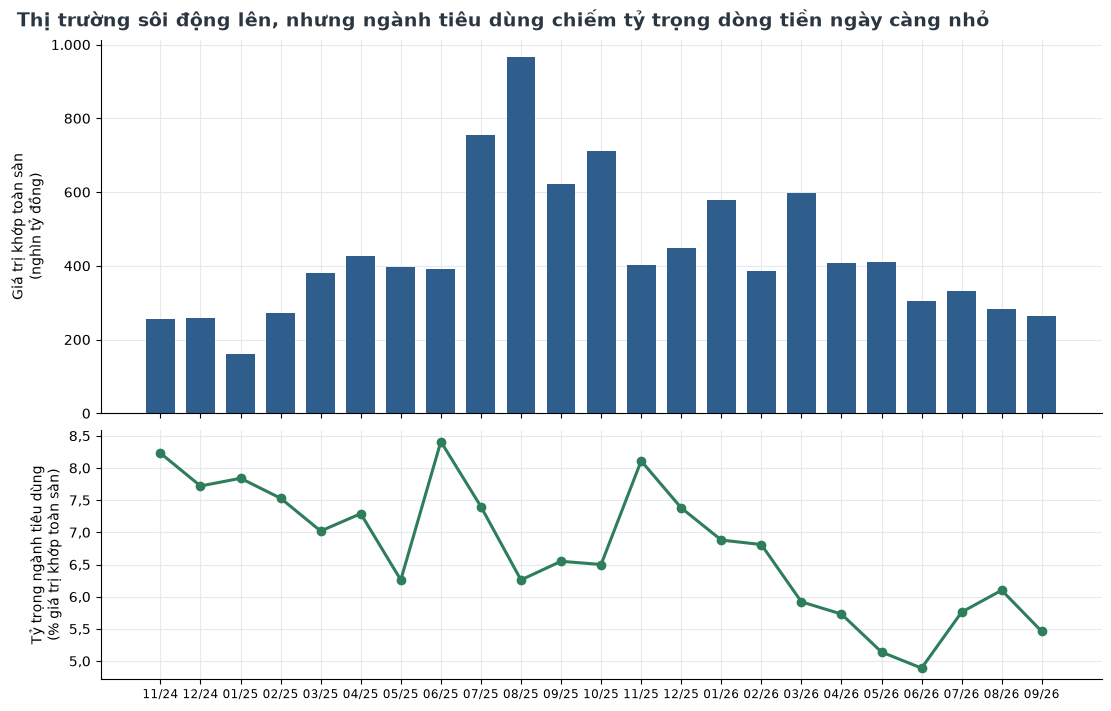

In [5]:
x = np.arange(len(thang_du))

fig, (ax_tren, ax_duoi) = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                                       gridspec_kw={"height_ratios": [3, 2]}, layout="constrained")

# panel trên: dòng tiền toàn sàn
ax_tren.bar(x, thang_du.Toan_san_ty / 1000, color=XANH_DUONG, width=0.72)
ax_tren.set_ylabel("Giá trị khớp toàn sàn\n(nghìn tỷ đồng)")
ax_tren.yaxis.set_major_formatter(FuncFormatter(lambda v, _: nghin(v)))

# panel dưới: tỷ trọng ngành tiêu dùng
ax_duoi.plot(x, thang_du.Ty_trong_nganh_pct, color=XANH_LA, lw=2.2, marker="o")
ax_duoi.set_ylabel("Tỷ trọng ngành tiêu dùng\n(% giá trị khớp toàn sàn)")
ax_duoi.yaxis.set_major_formatter(FuncFormatter(lambda v, _: so_vn(v, 1)))
ax_duoi.set_xticks(x)
ax_duoi.set_xticklabels(thang_du.Nhan, fontsize=8.5)

ve_xong(fig, "Thị trường sôi động lên, nhưng ngành tiêu dùng chiếm tỷ trọng dòng tiền ngày càng nhỏ",
        1)

### Hình 2: Dòng tiền chỉ số hóa: ngành Tiêu dùng so với toàn sàn
**Mục đích:** so tốc độ tăng/giảm dòng tiền của ngành với toàn sàn, thay vì so quy mô tuyệt đối.
**Dữ liệu:** Truy vấn 1 (`thang_du`).
**Phần được vẽ:** hai đường (toàn sàn, ngành), cùng quy về 100 ở tháng đầu tiên (11/2024).

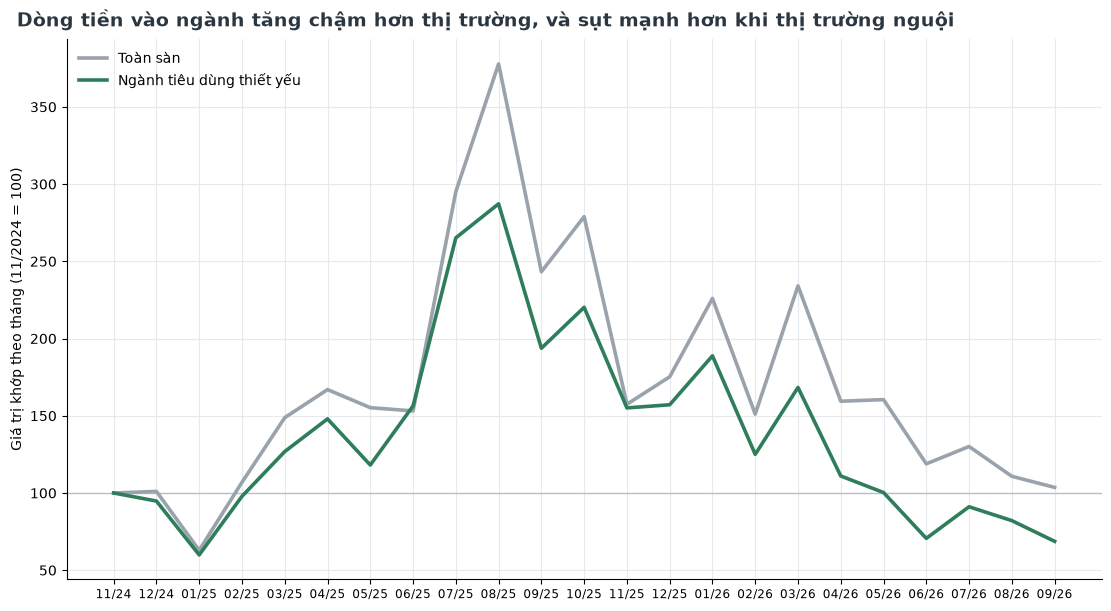

In [6]:
chi_so_san   = thang_du.Toan_san_ty / thang_du.Toan_san_ty[0] * 100            # 11/2024 = 100
chi_so_nganh = thang_du.Nganh_tieu_dung_ty / thang_du.Nganh_tieu_dung_ty[0] * 100
x = np.arange(len(thang_du))

fig, ax = plt.subplots(figsize=(11, 6), layout="constrained")
ax.axhline(100, color="#B8C0C7", lw=1)
ax.plot(x, chi_so_san,   color=XAM,     lw=2.6, label="Toàn sàn")
ax.plot(x, chi_so_nganh, color=XANH_LA, lw=2.6, label="Ngành tiêu dùng thiết yếu")
ax.set_xticks(x)
ax.set_xticklabels(thang_du.Nhan, fontsize=8.5)
ax.set_ylabel("Giá trị khớp theo tháng (11/2024 = 100)")
ax.legend(frameon=False, loc="upper left")

ve_xong(fig, "Dòng tiền vào ngành tăng chậm hơn thị trường, và sụt mạnh hơn khi thị trường nguội",
        2)

---
# Trang 2. Hiệu suất và rủi ro giá
**Luận điểm chính:** kết quả phụ thuộc vào việc chọn đúng mã, không phụ thuộc vào việc chọn ngành.

### Hình 3: Lợi nhuận trung bình và trung vị của ngành Tiêu dùng (30 mã)
**Mục đích:** cho thấy "lợi nhuận trung bình ngành" không đại diện cho mã điển hình nào.
**Dữ liệu:** Truy vấn 3 (`q3`) và Truy vấn 6 (`q6`).
**Phần được vẽ:** mỗi mã một dòng, xếp từ lợi nhuận cao xuống thấp (xanh = lời, đỏ = lỗ); hai đường dọc là trung bình và trung vị.

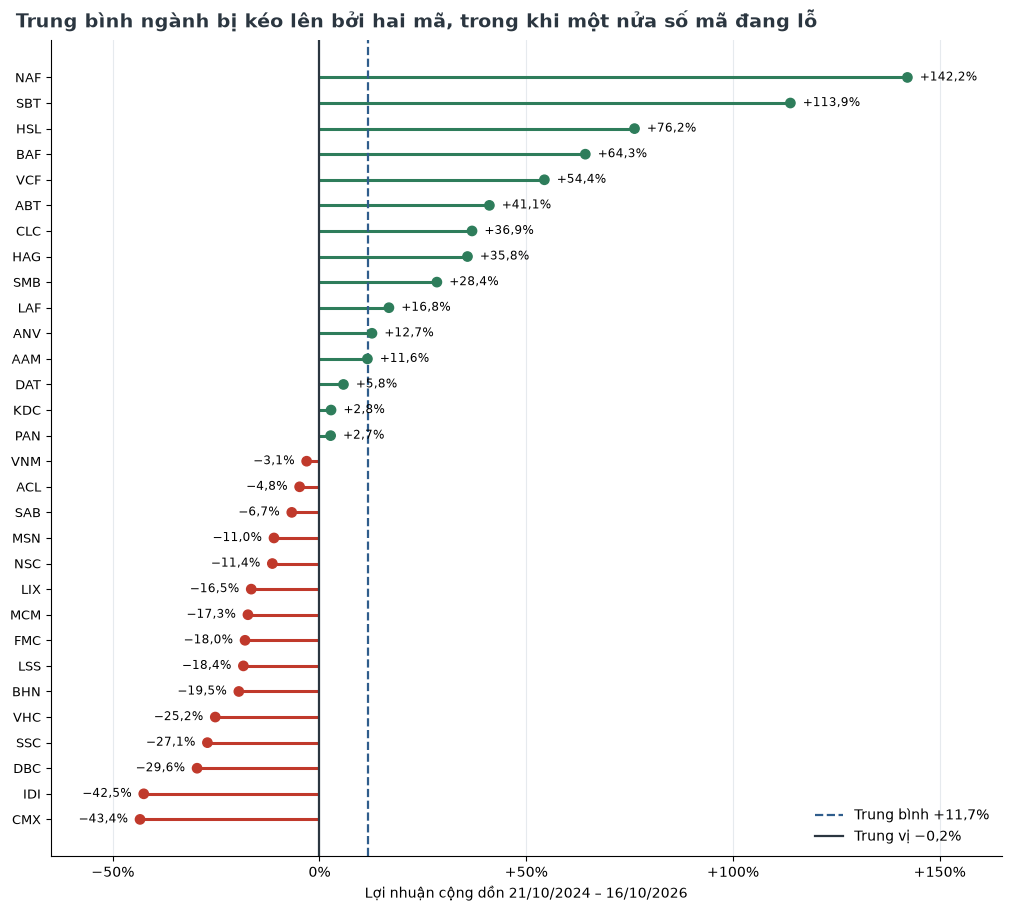

In [7]:
d = q3.sort_values("Loi_nhuan_pct", ascending=False).reset_index(drop=True)
y = np.arange(len(d))
mau = np.where(d.Loi_nhuan_pct > 0, XANH_LA, DO)
trung_binh, trung_vi = q6.Trung_binh_pct[0], q6.Trung_vi_pct[0]

fig, ax = plt.subplots(figsize=(10, 9), layout="constrained")
ax.hlines(y, 0, d.Loi_nhuan_pct, colors=mau, lw=2.2)                  # thân
ax.scatter(d.Loi_nhuan_pct, y, c=mau, s=45, zorder=3)                 # đầu
for yi, v in zip(y, d.Loi_nhuan_pct):                                 # nhãn giá trị
    ax.text(v + (3 if v > 0 else -3), yi, so_vn(v, 1, True) + "%",
            va="center", ha="left" if v > 0 else "right", fontsize=8.5)

ax.axvline(trung_binh, color=XANH_DUONG, ls="--", lw=1.6, label=f"Trung bình {so_vn(trung_binh, 1, True)}%")
ax.axvline(trung_vi,   color=DEN,        ls="-",  lw=1.6, label=f"Trung vị {so_vn(trung_vi, 1, True)}%")

ax.set_yticks(y)
ax.set_yticklabels(d.Ma, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(-65, 165)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: so_vn(v, 0, True) + "%"))
ax.set_xlabel("Lợi nhuận cộng dồn 21/10/2024 – 16/10/2026")
ax.legend(frameon=False, loc="lower right")

ve_xong(fig, "Trung bình ngành bị kéo lên bởi hai mã, trong khi một nửa số mã đang lỗ",
        3)

### Hình 4: Lợi nhuận trung bình và trung vị của ngành Tiêu dùng
**Mục đích:** cho thấy "lợi nhuận trung bình ngành" không đại diện cho mã điển hình: hai con số lệch nhau.
**Dữ liệu:** Truy vấn 6 (`q6`: `Trung_binh_pct`, `Trung_vi_pct`).
**Phần được vẽ:** hai ô KPI đặt cạnh nhau (trung bình bên trái, trung vị bên phải), không có tiêu đề và không có biểu đồ.

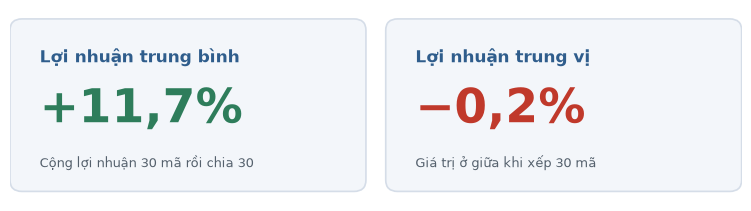

In [8]:
from matplotlib.patches import FancyBboxPatch

trung_binh, trung_vi = q6.Trung_binh_pct[0], q6.Trung_vi_pct[0]       # lấy trực tiếp từ Truy vấn 6

# mỗi ô: (nhãn, giá trị, mô tả ngắn, màu số)
cac_o = [("Lợi nhuận trung bình", trung_binh, "Cộng lợi nhuận 30 mã rồi chia 30", XANH_LA if trung_binh > 0 else DO),
         ("Lợi nhuận trung vị",   trung_vi,   "Giá trị ở giữa khi xếp 30 mã", XANH_LA if trung_vi > 0 else DO)]

# vẽ trên khung tính bằng inch (7,4 x 2,0) để góc bo tròn không bị méo
fig, ax = plt.subplots(figsize=(7.4, 2.0), layout="constrained")
ax.set_xlim(0, 7.4); ax.set_ylim(0, 2.0); ax.axis("off")

for i, (nhan, gia_tri, mo_ta, mau) in enumerate(cac_o):
    x0 = i * 3.8                                                    # ô thứ 2 cách ô thứ 1 một khoảng nhỏ
    ax.add_patch(FancyBboxPatch((x0, 0.1), 3.6, 1.8, boxstyle="round,pad=0,rounding_size=0.12",
                                fc="#F3F6FA", ec="#D5DDE8", lw=1.2))
    ax.text(x0 + 0.3, 1.5,  nhan, fontsize=12, fontweight="bold", color=XANH_DUONG, va="center")
    ax.text(x0 + 0.3, 0.95, so_vn(gia_tri, 1, True) + "%", fontsize=34, fontweight="bold", color=mau, va="center")
    ax.text(x0 + 0.3, 0.4,  mo_ta, fontsize=9, color="#55616D", va="center")

luu_hinh(fig, 4, dpi=200)
plt.show()
plt.close(fig)

### Hình 5: Lợi nhuận trung bình và trung vị của ngành (bỏ NAF và SBT)
**Mục đích:** cho thấy trung bình ngành giảm mạnh khi bỏ hai mã lời lớn nhất, và trung vị âm sâu hơn.
**Dữ liệu:** Truy vấn 3 (`q3`), loại hai mã NAF và SBT rồi tính lại trung bình và trung vị của 28 mã còn lại.
**Phần được vẽ:** hai ô KPI đặt cạnh nhau (trung bình bên trái, trung vị bên phải), cùng kiểu với Hình 4.

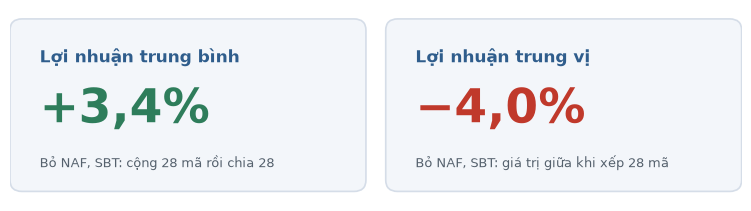

In [9]:
from matplotlib.patches import FancyBboxPatch

# bỏ 2 mã lời lớn nhất (NAF, SBT) khỏi 30 mã rồi tính lại
con_lai = q3[~q3.Ma.isin(["NAF", "SBT"])]
trung_binh, trung_vi = con_lai.Loi_nhuan_pct.mean(), con_lai.Loi_nhuan_pct.median()

# mỗi ô: (nhãn, giá trị, mô tả ngắn, màu số)
cac_o = [("Lợi nhuận trung bình", trung_binh, "Bỏ NAF, SBT: cộng 28 mã rồi chia 28", XANH_LA if trung_binh > 0 else DO),
         ("Lợi nhuận trung vị",   trung_vi,   "Bỏ NAF, SBT: giá trị giữa khi xếp 28 mã", XANH_LA if trung_vi > 0 else DO)]

# vẽ trên khung tính bằng inch (7,4 x 2,0) để góc bo tròn không bị méo
fig, ax = plt.subplots(figsize=(7.4, 2.0), layout="constrained")
ax.set_xlim(0, 7.4); ax.set_ylim(0, 2.0); ax.axis("off")

for i, (nhan, gia_tri, mo_ta, mau) in enumerate(cac_o):
    x0 = i * 3.8                                                    # ô thứ 2 cách ô thứ 1 một khoảng nhỏ
    ax.add_patch(FancyBboxPatch((x0, 0.1), 3.6, 1.8, boxstyle="round,pad=0,rounding_size=0.12",
                                fc="#F3F6FA", ec="#D5DDE8", lw=1.2))
    ax.text(x0 + 0.3, 1.5,  nhan, fontsize=12, fontweight="bold", color=XANH_DUONG, va="center")
    ax.text(x0 + 0.3, 0.95, so_vn(gia_tri, 1, True) + "%", fontsize=34, fontweight="bold", color=mau, va="center")
    ax.text(x0 + 0.3, 0.4,  mo_ta, fontsize=9, color="#55616D", va="center")

luu_hinh(fig, 5, dpi=200)
plt.show()
plt.close(fig)

### Hình 6: Ma trận lợi nhuận và Max Drawdown theo nhóm
**Mục đích:** cho thấy lợi nhuận một mình chưa đủ, cần xem thêm mức sụt giảm sâu nhất từ đỉnh (Max Drawdown).
**Dữ liệu:** Truy vấn 5 (`q5`, 35 mã).
**Phần được vẽ:** mỗi mã một điểm (trục X: Max Drawdown, càng sang phải càng nông; trục Y: lợi nhuận), màu theo nhóm. Tam giác rỗng là mã niêm yết mới. Hai đường kẻ là lợi nhuận = 0 và Max Drawdown = −30%.

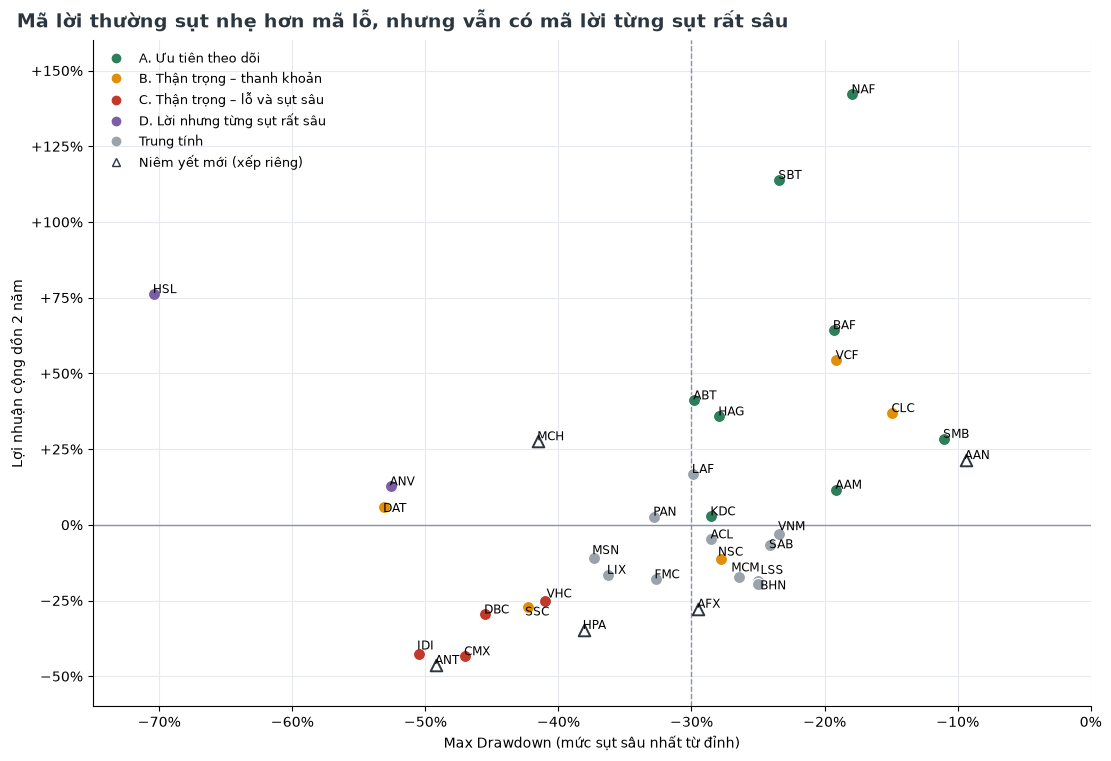

In [10]:
fig, ax = plt.subplots(figsize=(11, 7.5), layout="constrained")
ax.axhline(0,   color="#8A949E", lw=1)
ax.axvline(-30, color="#8A949E", lw=1, ls="--")

# mỗi nhóm một màu; mã niêm yết mới vẽ bằng tam giác rỗng
for nhom, bang in q5.groupby("Nhom_ma"):
    if nhom == "N":
        ax.scatter(bang.Max_Drawdown_pct, bang.Loi_nhuan_pct, marker="^", s=70,
                   facecolor="white", edgecolor=DEN, lw=1.4, zorder=3)
    else:
        ax.scatter(bang.Max_Drawdown_pct, bang.Loi_nhuan_pct, s=75, color=MAU_NHOM[nhom],
                   edgecolor="white", lw=0.8, zorder=3)

# nhãn mã (adjust_text tự đẩy nhãn ra để không chồng nhau)
nhan = [ax.text(r.Max_Drawdown_pct, r.Loi_nhuan_pct, r.Ma, fontsize=8.5) for r in q5.itertuples()]
adjust_text(nhan, ax=ax, arrowprops=dict(arrowstyle="-", color="#999", lw=0.5))

ax.set_xlim(-75, 0)
ax.set_ylim(-60, 160)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: so_vn(v, 0) + "%"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: so_vn(v, 0, True) + "%"))
ax.set_xlabel("Max Drawdown (mức sụt sâu nhất từ đỉnh)")
ax.set_ylabel("Lợi nhuận cộng dồn 2 năm")

chu_thich = [Line2D([], [], marker="o", ls="", color=MAU_NHOM[k], label=TEN_NHOM[k]) for k in "ABCDT"]
chu_thich.append(Line2D([], [], marker="^", ls="", mfc="white", mec=DEN, color=DEN, label=TEN_NHOM["N"]))
ax.legend(handles=chu_thich, frameon=False, fontsize=9, loc="upper left")

ve_xong(fig, "Mã lời thường sụt nhẹ hơn mã lỗ, nhưng vẫn có mã lời từng sụt rất sâu",
        6)

### Hình 7: Lợi nhuận trên Max Drawdown của các mã có lợi nhuận dương
**Mục đích:** cho thấy xếp hạng theo lợi nhuận thô khác với xếp hạng khi tính cả rủi ro. Chỉ số = lợi nhuận / |Max Drawdown|.
**Dữ liệu:** Truy vấn 3 (`q3`), chỉ lấy mã có lợi nhuận dương.
**Phần được vẽ:** mỗi mã một thanh, độ dài là chỉ số. Nhãn "LN #a → #b" là hạng theo lợi nhuận rồi hạng theo chỉ số. Xanh = lên hạng từ 2 bậc, đỏ = xuống hạng từ 2 bậc.

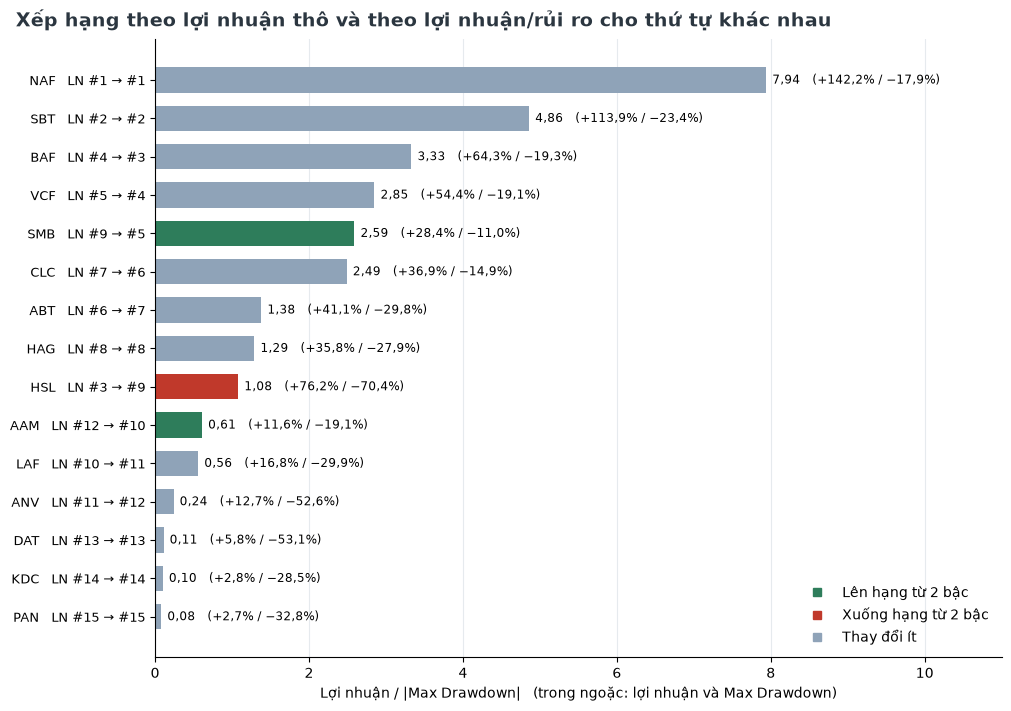

In [11]:
d = q3[q3.Loi_nhuan_pct > 0].sort_values("Loi_tren_sut", ascending=False).reset_index(drop=True)
y = np.arange(len(d))

# so hạng theo lợi nhuận với hạng theo chỉ số: dương = lên hạng, âm = xuống hạng
doi_hang = d.Hang_theo_loi_nhuan - d.Hang_theo_loi_tren_sut
mau = np.where(doi_hang >= 2, XANH_LA, np.where(doi_hang <= -2, DO, "#8FA3B8"))

fig, ax = plt.subplots(figsize=(10, 7), layout="constrained")
ax.barh(y, d.Loi_tren_sut, color=mau, height=0.66)
for yi, r in zip(y, d.itertuples()):
    ax.text(r.Loi_tren_sut + 0.08, yi, f"{so_vn(r.Loi_tren_sut, 2)}   ({so_vn(r.Loi_nhuan_pct, 1, True)}% / {so_vn(r.Max_Drawdown_pct, 1)}%)",
            va="center", fontsize=8.8)

ax.set_yticks(y)
ax.set_yticklabels([f"{r.Ma}   LN #{r.Hang_theo_loi_nhuan} → #{r.Hang_theo_loi_tren_sut}" for r in d.itertuples()], fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 11)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Lợi nhuận / |Max Drawdown|   (trong ngoặc: lợi nhuận và Max Drawdown)")

chu_thich = [Line2D([], [], marker="s", ls="", color=XANH_LA,  label="Lên hạng từ 2 bậc"),
             Line2D([], [], marker="s", ls="", color=DO,       label="Xuống hạng từ 2 bậc"),
             Line2D([], [], marker="s", ls="", color="#8FA3B8", label="Thay đổi ít")]
ax.legend(handles=chu_thich, frameon=False, loc="lower right")

ve_xong(fig, "Xếp hạng theo lợi nhuận thô và theo lợi nhuận/rủi ro cho thứ tự khác nhau",
        7)

---
# Trang 3. Rủi ro thanh khoản
**Luận điểm chính:** lợi nhuận trên giá chỉ có ý nghĩa khi mã giao dịch đủ đều.

### Hình 9: Tỷ lệ phiên không giao dịch của 8 mã cảnh báo thanh khoản
**Mục đích:** xác định mã nào thiếu thanh khoản và mức độ nghiêm trọng.
**Dữ liệu:** Truy vấn 4 (`q4`, 8 mã có từ 20 phiên không giao dịch trở lên).
**Phần được vẽ:** mỗi mã một thanh 100% số phiên; phần đỏ là phiên không giao dịch; nhãn ghi tỷ lệ và (số phiên trống / số phiên).

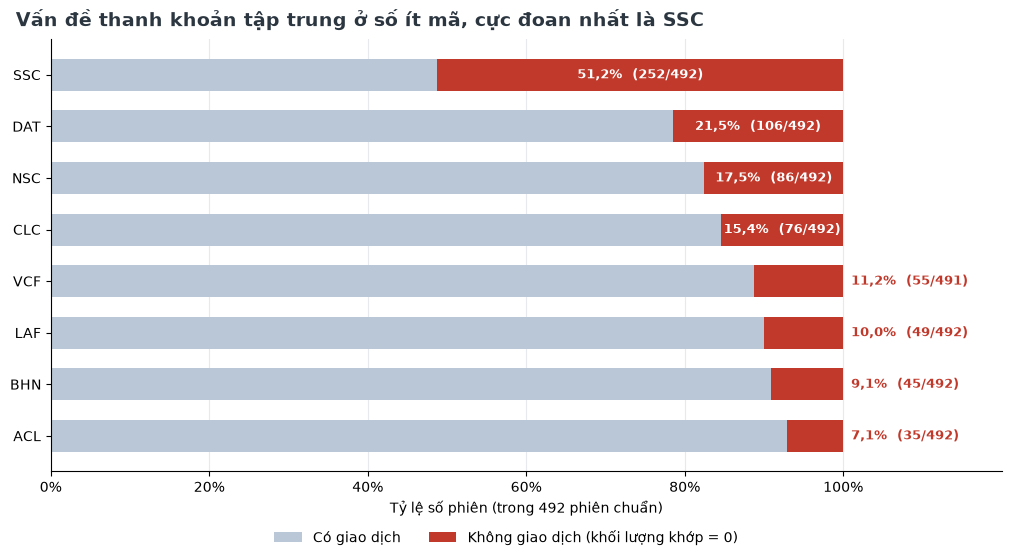

In [12]:
d = q4.sort_values("Zero_Volume_Days", ascending=False).reset_index(drop=True)
y = np.arange(len(d))
ty_le_trong = d.Ty_le_phien_trong_pct

fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
ax.barh(y, 100 - ty_le_trong, color="#B9C7D6", height=0.62, label="Có giao dịch")
ax.barh(y, ty_le_trong, left=100 - ty_le_trong, color=DO, height=0.62, label="Không giao dịch (khối lượng khớp = 0)")

for yi, r in zip(y, d.itertuples()):
    nhan = f"{so_vn(r.Ty_le_phien_trong_pct)}%  ({r.Zero_Volume_Days}/{r.So_phien})"
    if r.Ty_le_phien_trong_pct > 14:          # thanh đủ rộng: ghi nhãn trong thanh đỏ
        ax.text(100 - r.Ty_le_phien_trong_pct / 2, yi, nhan, ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    else:                                     # thanh hẹp: ghi nhãn bên phải
        ax.text(101, yi, nhan, ha="left", va="center", color=DO, fontsize=9, fontweight="bold")

ax.set_yticks(y)
ax.set_yticklabels(d.Ma, fontsize=10)
ax.invert_yaxis()
ax.set_xlim(0, 120)
ax.set_xticks(range(0, 101, 20))
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v)}%"))
ax.grid(axis="y", visible=False)
ax.set_xlabel("Tỷ lệ số phiên (trong 492 phiên chuẩn)")
fig.legend(loc="outside lower center", ncol=2, frameon=False)

ve_xong(fig, "Vấn đề thanh khoản tập trung ở số ít mã, cực đoan nhất là SSC",
        9)

### Hình 8: Tổng giá trị khớp lệnh và lợi nhuận của 30 mã
**Mục đích:** cùng một hình trả lời hai câu: mã giao dịch nhiều có lời không, và mã lời cao có giao dịch đủ để thoát vị thế không.
**Dữ liệu:** Truy vấn 5 (`q5`: lợi nhuận, nhóm) ghép Truy vấn 7 (`q7`: tổng giá trị khớp).
**Phần được vẽ:** mỗi mã một điểm (trục X: tổng giá trị khớp 2 năm, thang log; trục Y: lợi nhuận). Cam = 3 mã khớp nhiều nhất, đỏ = nhóm B (thận trọng thanh khoản). Chỉ vẽ 30 mã đủ dữ liệu.

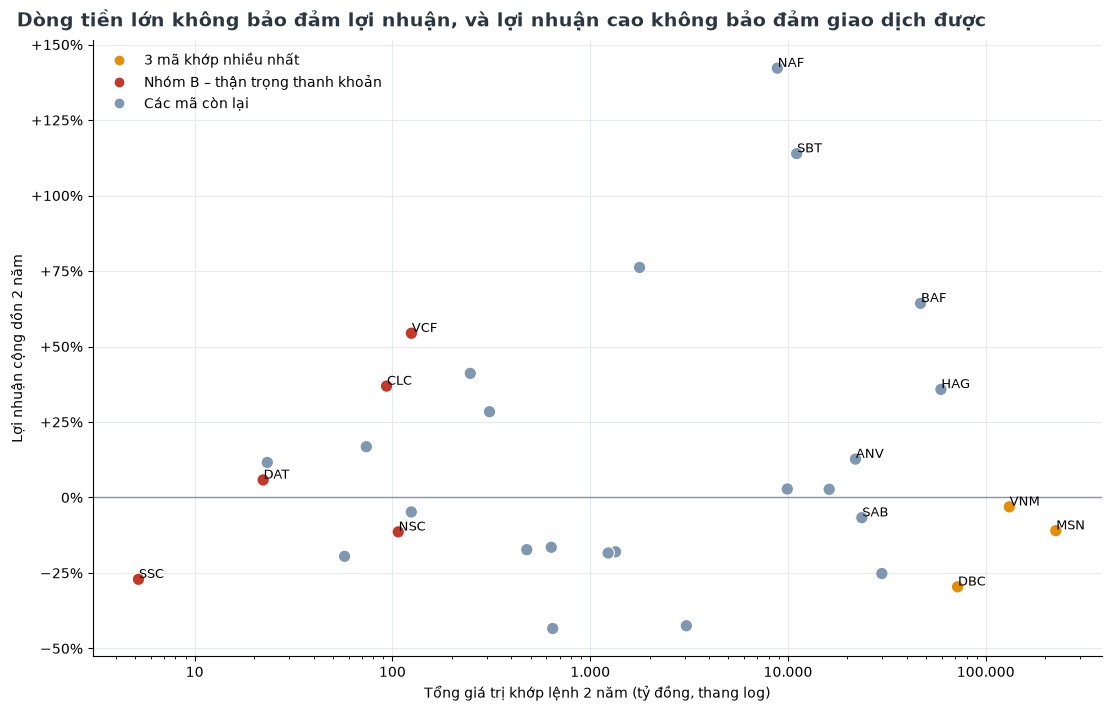

In [13]:
# ghép lợi nhuận + nhóm (q5) với tổng giá trị khớp (q7), bỏ 5 mã niêm yết mới
d = q5.set_index("Ma").join(q7.set_index("Ma"))
d = d[d.Nhom_ma != "N"]

top3 = d.Tong_gia_tri_khop_ty.nlargest(3).index          # 3 mã khớp nhiều nhất
def mau_diem(ma, nhom):
    if nhom == "B":  return DO                            # nhóm thận trọng thanh khoản
    if ma in top3:   return CAM
    return "#7F97B0"

fig, ax = plt.subplots(figsize=(11, 7), layout="constrained")
ax.set_xscale("log")
ax.axhline(0, color="#8A949E", lw=1)
ax.scatter(d.Tong_gia_tri_khop_ty, d.Loi_nhuan_pct, s=80, edgecolor="white", lw=0.8, zorder=3,
           c=[mau_diem(ma, nhom) for ma, nhom in zip(d.index, d.Nhom_ma)])

# chỉ gắn nhãn các mã cần chú ý
can_nhan = set(top3) | {"SAB", "HAG", "BAF", "NAF", "SBT", "ANV"} | set(d.index[d.Nhom_ma == "B"])
nhan = [ax.text(r.Tong_gia_tri_khop_ty, r.Loi_nhuan_pct, ma, fontsize=9) for ma, r in d.iterrows() if ma in can_nhan]
adjust_text(nhan, ax=ax, arrowprops=dict(arrowstyle="-", color="#999", lw=0.5))

ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: nghin(v)))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: so_vn(v, 0, True) + "%"))
ax.set_xlabel("Tổng giá trị khớp lệnh 2 năm (tỷ đồng, thang log)")
ax.set_ylabel("Lợi nhuận cộng dồn 2 năm")

chu_thich = [Line2D([], [], marker="o", ls="", color=CAM,       label="3 mã khớp nhiều nhất"),
             Line2D([], [], marker="o", ls="", color=DO,        label="Nhóm B – thận trọng thanh khoản"),
             Line2D([], [], marker="o", ls="", color="#7F97B0", label="Các mã còn lại")]
ax.legend(handles=chu_thich, frameon=False, loc="upper left")

ve_xong(fig, "Dòng tiền lớn không bảo đảm lợi nhuận, và lợi nhuận cao không bảo đảm giao dịch được",
        8)

### Hình 10: Giá và giá trị khớp theo ngày: SSC so với SBT
**Mục đích:** cho thấy giá "đứng yên" ở mã thiếu thanh khoản có thể chỉ do không ai giao dịch. SSC đặt cạnh SBT (không có phiên trống) để so sánh.
**Dữ liệu:** Truy vấn 8 (`q8`).
**Phần được vẽ:** mỗi cột một mã (trái SSC, phải SBT). Hàng trên là chỉ số giá điều chỉnh (ngày đầu = 100) kèm chấm đỏ ở các phiên không giao dịch; hàng dưới là giá trị khớp theo ngày. Mỗi cột có thang riêng.

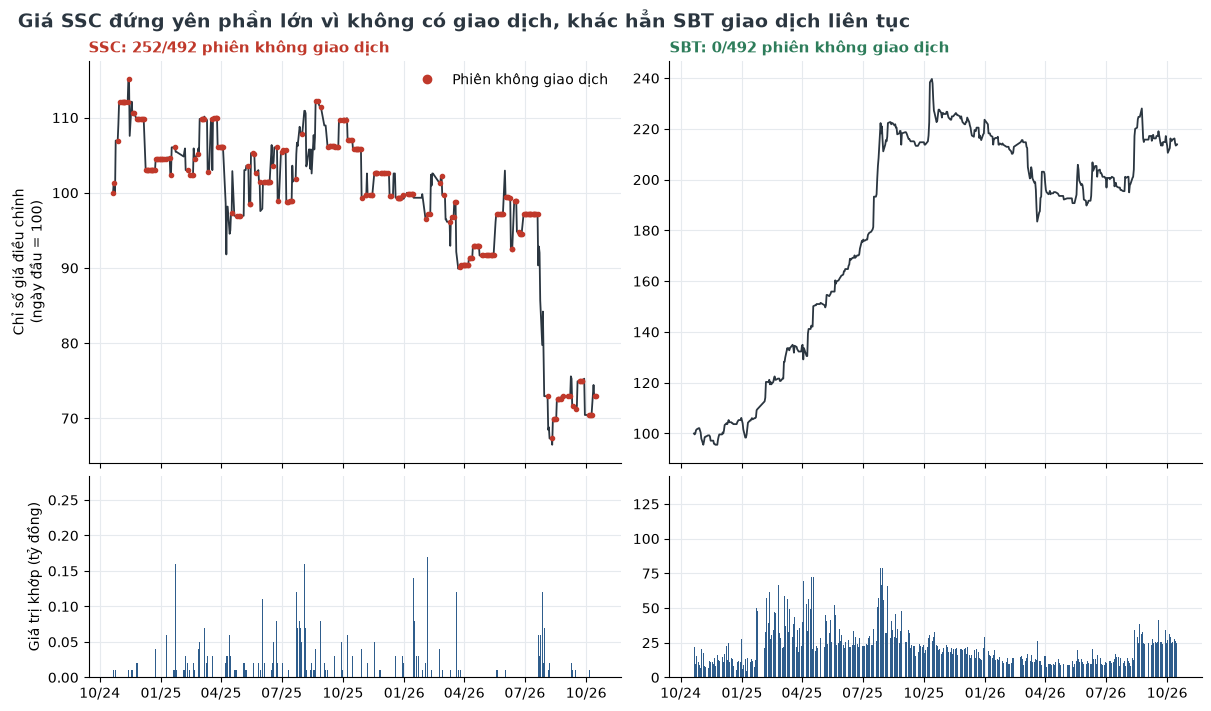

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True,
                         gridspec_kw={"height_ratios": [2, 1]}, layout="constrained")

for cot, (ma, mau_tieu_de) in enumerate([("SSC", DO), ("SBT", XANH_LA)]):
    d = q8[q8.Ma == ma]
    phien_trong = d[d.Is_Zero_Volume == 1]                 # phiên không giao dịch
    ax_gia, ax_gt = axes[0, cot], axes[1, cot]

    # hàng trên: chỉ số giá + chấm đỏ ở phiên không giao dịch
    ax_gia.plot(d.Ngay, d.Chi_so_gia, color=DEN, lw=1.3)
    ax_gia.scatter(phien_trong.Ngay, phien_trong.Chi_so_gia, color=DO, s=9, zorder=3)
    ax_gia.set_title(f"{ma}: {len(phien_trong)}/{len(d)} phiên không giao dịch", loc="left",
                     fontsize=11, color=mau_tieu_de, fontweight="bold")
    ax_gia.set_ylabel("Chỉ số giá điều chỉnh\n(ngày đầu = 100)" if cot == 0 else "")

    # hàng dưới: giá trị khớp theo ngày
    ax_gt.bar(d.Ngay, d.GT_khop, width=1.0, color=XANH_DUONG)
    ax_gt.set_ylabel("Giá trị khớp (tỷ đồng)" if cot == 0 else "")
    ax_gt.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax_gt.xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))

axes[0, 0].legend(handles=[Line2D([], [], marker="o", ls="", color=DO, label="Phiên không giao dịch")],
                  frameon=False, loc="upper right")

ve_xong(fig, "Giá SSC đứng yên phần lớn vì không có giao dịch, khác hẳn SBT giao dịch liên tục",
        10)